# Benchmark, round two: four methods, three budgets, evaluated on the test split

The second round changes three things against notebook 06 and keeps
everything else. First, the checkpoints are the 4000 sample, 70/15/15 ones
from notebook 08, and every explained document comes from the test split
alone, 300 stratified of its 600, three times the previous observation
count. Second, the method roster gains an explicit **random** baseline, one
standard gaussian draw per word, mean zero and unit variance, seeded; with a
method independent random arm in the comparison, the per source shuffled
controls of round one are retired. Third, the budget axis becomes three
points, 50, 200 and 500 evaluations for SHAP and LIME; occlusion keeps its
structural cost of one prediction per word, and comparisons across methods
are made at the 500 budget.

Eight attribution sources per dataset, each swept over chunk sizes 1, 4 and
8, all three combinations, both directions, thresholds 20 to 80. Every
attribution payload and every per source sweep is cached separately, so this
long computation survives interruption and reruns only what is missing. All
presentation is on the relative scale, shift as a percentage of the model's
original predicted class confidence.

## Configuration

In [1]:
from pathlib import Path

from textfaith.faithfulness import ABSOLUTE_SUM, MAX_ABSOLUTE, SUM_ABSOLUTE

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ARTIFACTS_DIRECTORY = PROJECT_ROOT / "artifacts"

DATASET_DIRECTORIES = {
    "imdb": ARTIFACTS_DIRECTORY / "imdb_4000",
    "yelp": ARTIFACTS_DIRECTORY / "yelp_4000",
    "agnews": ARTIFACTS_DIRECTORY / "agnews_4000",
}

OBSERVATION_COUNT = 300
METHOD_BUDGET_PAIRS = [
    ("random", None),
    ("occlusion", None),
    ("shap", 500),
    ("shap", 200),
    ("shap", 50),
    ("lime", 500),
    ("lime", 200),
    ("lime", 50),
]
PERCENTILES = [20, 40, 60, 80]
CHUNK_SIZES = [1, 4, 8]
COMBINATIONS = [ABSOLUTE_SUM, SUM_ABSOLUTE, MAX_ABSOLUTE]
RANDOM_SEED = 42

TIDY_RESULTS_PATH = ARTIFACTS_DIRECTORY / "faithfulness_results_v2.parquet"
TIMING_RESULTS_PATH = ARTIFACTS_DIRECTORY / "timing_results_v2.parquet"
METHOD_COMPARISON_PATH = ARTIFACTS_DIRECTORY / "method_comparison_v2.parquet"

print(f"Datasets: {list(DATASET_DIRECTORIES)}")
print(f"Sources: {[pair[0] if pair[1] is None else f'{pair[0]}_{pair[1]}' for pair in METHOD_BUDGET_PAIRS]}")
print(f"{OBSERVATION_COUNT} test documents per dataset, thresholds {PERCENTILES}")

Datasets: ['imdb', 'yelp', 'agnews']
Sources: ['random', 'occlusion', 'shap_500', 'shap_200', 'shap_50', 'lime_500', 'lime_200', 'lime_50']
300 test documents per dataset, thresholds [20, 40, 60, 80]


/home/user/projects/shapley/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Run the experiment

One loop, everything load-or-compute at per source granularity: one cache per
attribution payload, one cache per source's sweep. The random baseline costs
zero model predictions, occlusion one per word, and the budget for SHAP is a
cap while for LIME it is exact, so the timing table below reports the
predictions actually made. The percentile 0 invariant runs once per dataset
on the random arrays, the newest path through the machinery.

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from textfaith.checkpoint import load_predictor
from textfaith.experiment import (
    compute_original_probabilities,
    compute_timed_attributions,
    load_or_compute,
    records_to_tidy_frame,
    sweep_faithfulness,
)
from textfaith.faithfulness import build_word_masker, measure_sufficiency

masker = build_word_masker()
percentile_label = "-".join(str(percentile) for percentile in PERCENTILES)

tidy_frames = []
timing_rows = []
original_probability_frames = []

for dataset_name, directory in DATASET_DIRECTORIES.items():
    predict_probabilities, _ = load_predictor(directory)
    test_reviews = pd.read_parquet(directory / "test.parquet")
    sampled_reviews, _ = train_test_split(
        test_reviews,
        train_size=OBSERVATION_COUNT,
        random_state=RANDOM_SEED,
        stratify=test_reviews["label"],
    )
    texts = sampled_reviews["text"].tolist()

    dataset_records = []
    attributions_by_source = {}
    for method_name, budget in METHOD_BUDGET_PAIRS:
        if budget is None:
            source_label = method_name
            budget_label = "none" if method_name == "random" else "word_count"
            cache_path = directory / (
                f"{method_name}_attributions_{OBSERVATION_COUNT}obs.joblib"
            )
        else:
            source_label = f"{method_name}_{budget}"
            budget_label = str(budget)
            budget_unit = "evals" if method_name == "shap" else "samples"
            cache_path = directory / (
                f"{method_name}_attributions_{OBSERVATION_COUNT}obs_"
                f"{budget}{budget_unit}.joblib"
            )
        was_cached = cache_path.exists()
        payload = load_or_compute(
            cache_path,
            lambda: compute_timed_attributions(
                method_name, predict_probabilities, texts, masker, budget, RANDOM_SEED
            ),
        )
        attributions_by_source[source_label] = payload["attributions"]
        timing_rows.append(
            {
                "dataset": dataset_name,
                "method": method_name,
                "budget": budget_label,
                "wall_seconds": payload["wall_seconds"],
                "prediction_count": payload["prediction_count"],
            }
        )
        for text, attribution in zip(texts, payload["attributions"]):
            assert len(attribution) == len(masker.data_transform(text)[0]), (
                f"{dataset_name}/{source_label}: attribution misaligned with masker words"
            )
        print(
            f"{dataset_name}/{source_label}: "
            f"{'cached' if was_cached else 'computed'}, "
            f"{payload['wall_seconds'] / 60:.1f} minutes, "
            f"{payload['prediction_count']} predictions"
        )

        records_path = directory / (
            f"faithfulness_records_v2_{source_label}_{OBSERVATION_COUNT}obs_"
            f"{percentile_label}pct.joblib"
        )
        sweep_was_cached = records_path.exists()
        source_records = load_or_compute(
            records_path,
            lambda: sweep_faithfulness(
                predict_probabilities, texts, masker,
                {source_label: payload["attributions"]},
                PERCENTILES, CHUNK_SIZES, COMBINATIONS, RANDOM_SEED,
                include_shuffled_controls=False,
            ),
        )
        dataset_records.extend(source_records)
        print(
            f"{dataset_name}/{source_label}: sweep "
            f"{'cached' if sweep_was_cached else 'computed'}, "
            f"{len(source_records)} grid cells"
        )

    no_cut_shift = measure_sufficiency(
        predict_probabilities, texts, [0], masker, attributions_by_source["random"]
    )
    assert np.allclose(no_cut_shift, 0, atol=1e-6), "Cutting nothing moved the output"

    originals = load_or_compute(
        directory / f"original_probabilities_{OBSERVATION_COUNT}obs.joblib",
        lambda: compute_original_probabilities(predict_probabilities, texts),
    )
    original_probability_frames.append(originals.assign(dataset=dataset_name))
    tidy_frames.append(records_to_tidy_frame(dataset_records, dataset_name, PERCENTILES))
    print(f"{dataset_name}: {len(dataset_records)} grid cells measured in total")

original_probabilities = pd.concat(original_probability_frames, ignore_index=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 20285.98it/s]

imdb/random: computed, 0.0 minutes, 0 predictions


imdb/random: sweep computed, 18 grid cells


imdb/occlusion: computed, 35.9 minutes, 52838 predictions


...

agnews/lime_200: computed, 13.9 minutes, 60300 predictions


agnews/lime_200: sweep computed, 18 grid cells


agnews/lime_50: computed, 4.2 minutes, 15300 predictions


agnews/lime_50: sweep computed, 18 grid cells


agnews: 144 grid cells measured in total


## Speed of execution: seconds per review

The question a practitioner asks is what one explained document costs. The
table reports it for SHAP and LIME at each budget; occlusion and the free
random baseline are omitted because their cost is structural, not a choice.
Wall clock on the same 8 core CPU machine throughout.

In [3]:
timing = pd.DataFrame(timing_rows)
timing["seconds_per_review"] = timing["wall_seconds"] / OBSERVATION_COUNT
timing["predictions_per_second"] = (
    timing["prediction_count"] / timing["wall_seconds"]
)
timing.set_index(["dataset", "method", "budget"]).to_parquet(TIMING_RESULTS_PATH)
print(f"Saved {TIMING_RESULTS_PATH}")

seconds_per_review = (
    timing[timing["method"].isin(["shap", "lime"])]
    .pivot_table(
        index=["dataset", "method"], columns="budget", values="seconds_per_review"
    )
    .reindex(columns=["50", "200", "500"])
)
seconds_per_review.round(2)

Saved /home/user/projects/shapley/artifacts/timing_results_v2.parquet


budget            50    200    500
dataset method                    
agnews  lime    0.85   2.79   6.66
        shap    0.45   1.50   3.72
imdb    lime    3.44  11.96  28.58
        shap    1.49   5.21  11.53
yelp    lime    2.54   8.67  20.83
        shap    1.10   3.68   8.02

## Tidy results

One row per dataset, source, chunk size, combination, direction, threshold
and observation, with the raw probability shift and its relative form, the
share of the model's original confidence the cut moved. The relative form is
the presentation scale everywhere below.

In [4]:
from textfaith.experiment import attach_relative_shift

tidy = pd.concat(tidy_frames, ignore_index=True)
tidy = attach_relative_shift(tidy, original_probabilities)

expected_rows = (
    len(DATASET_DIRECTORIES) * len(METHOD_BUDGET_PAIRS) * len(CHUNK_SIZES)
    * len(COMBINATIONS) * 2 * len(PERCENTILES) * OBSERVATION_COUNT
)
assert len(tidy) == expected_rows, (len(tidy), expected_rows)
assert not tidy.isnull().any().any(), "Tidy frame contains nulls"
assert tidy["relative_shift"].between(0, 1).all()

tidy.to_parquet(TIDY_RESULTS_PATH, index=False)
print(f"Saved {len(tidy)} rows to {TIDY_RESULTS_PATH}")
tidy.head(6)

Saved 518400 rows to /home/user/projects/shapley/artifacts/faithfulness_results_v2.parquet


,dataset,source,method,budget,is_random,chunk_size,combination,direction,percentile,observation_index,probability_shift,original_probability,relative_shift
0,imdb,random,random,none,False,1,absolute_sum,sufficiency,20,0,0.079488,0.910047,0.087345
1,imdb,random,random,none,False,1,absolute_sum,sufficiency,40,0,0.212090,0.910047,0.233054
2,imdb,random,random,none,False,1,absolute_sum,sufficiency,60,0,0.619708,0.910047,0.680963
3,imdb,random,random,none,False,1,absolute_sum,sufficiency,80,0,0.576657,0.910047,0.633656
4,imdb,random,random,none,False,1,absolute_sum,sufficiency,20,1,0.080672,0.845923,0.095366
5,imdb,random,random,none,False,1,absolute_sum,sufficiency,40,1,0.157848,0.845923,0.186599


## The landscape in percent

Mean shift as a percentage of the model's confidence for the four methods at
their comparison budget, `absolute_sum`, averaged over thresholds and
observations. Random is the floor sufficiency must beat downward and
comprehensiveness upward.

In [5]:
MAIN_SOURCES = ["shap_500", "lime_500", "occlusion", "random"]

relative_table = (
    tidy[
        tidy["source"].isin(MAIN_SOURCES)
        & (tidy["combination"] == ABSOLUTE_SUM)
    ]
    .pivot_table(
        values="relative_shift",
        index=["dataset", "chunk_size"],
        columns=["direction", "source"],
        aggfunc="mean",
    )
    .reindex(
        columns=pd.MultiIndex.from_product(
            [["sufficiency", "comprehensiveness"], MAIN_SOURCES]
        )
    )
)
(relative_table * 100).round(1)

sufficiency                           comprehensiveness  \
                      shap_500 lime_500 occlusion random          shap_500   
dataset chunk_size                                                           
agnews  1                  5.5      4.1       6.9   13.1              30.0   
        4                  5.5      5.2       7.8    9.7              18.3   
        8                  5.8      5.3       7.9    9.1              15.6   
imdb    1                  8.3     11.5      10.6   21.4              37.2   
        4                  7.7      7.9       9.9   14.8              31.8   
        8                  7.5      7.8      10.6   13.9              27.4   
yelp    1                  6.2      9.9       8.5   20.3              39.3   
        4                  6.4      6.9       7.8   14.0              31.1   
        8                  5.8      5.9       8.8   12.3              23.8   

                                              
                   lime_500 occlusion random  
dataset chunk_size                            
agnews  1              27.5      19.1   11.9  
        4              18.1      13.1    9.9  
        8              15.4      12.3    9.5  
imdb    1              33.0      33.9   21.9  
        4              25.3      25.1   15.6  
        8              23.4      22.2   14.2  
yelp    1              35.6      30.1   20.2  
        4              25.6      21.4   12.9  
        8              21.8      18.3   12.2

## Pairwise comparisons

Twelve pairwise comparisons on the threshold averaged relative scores, each a
family of 54 conditions with its own Holm correction. Positive numbers always
favor the first named source. Three families test whether the metric makes
sense at all, every real method against the gaussian random baseline; one is
the head to head at the shared budget; two place occlusion; six trace the
budget ladders.

In [6]:
from textfaith.experiment import average_shifts_over_thresholds, compare_methods

SOURCE_PAIRS = [
    ("shap_500", "random"),
    ("lime_500", "random"),
    ("occlusion", "random"),
    ("shap_500", "lime_500"),
    ("occlusion", "shap_500"),
    ("occlusion", "lime_500"),
    ("shap_500", "shap_200"),
    ("shap_200", "shap_50"),
    ("shap_500", "shap_50"),
    ("lime_500", "lime_200"),
    ("lime_200", "lime_50"),
    ("lime_500", "lime_50"),
]

average_shifts = average_shifts_over_thresholds(tidy, value_column="relative_shift")
method_comparison = compare_methods(average_shifts, SOURCE_PAIRS)


def holm_significant(p_values, alpha=0.05):
    order = np.argsort(p_values)
    significant = np.zeros(len(p_values), dtype=bool)
    for rank, index in enumerate(order):
        if p_values[index] > alpha / (len(p_values) - rank):
            break
        significant[index] = True
    return significant


method_comparison["holm_significant"] = (
    method_comparison.groupby(level="comparison")["wilcoxon_p"]
    .transform(lambda p_values: holm_significant(p_values.to_numpy()))
)
method_comparison.to_parquet(METHOD_COMPARISON_PATH)
print(f"{len(method_comparison)} comparison rows saved to {METHOD_COMPARISON_PATH}")

display_comparison = method_comparison.copy()
for column in ["average_shift_first", "average_shift_second", "first_advantage"]:
    display_comparison[column] = display_comparison[column] * 100
display_comparison.round(2)

648 comparison rows saved to /home/user/projects/shapley/artifacts/method_comparison_v2.parquet


average_shift_first  \
comparison          dataset chunk_size combination  direction                                
shap_500 vs random  agnews  1          absolute_sum comprehensiveness                30.01   
                                                    sufficiency                       5.48   
                                       max_absolute comprehensiveness                30.01   
                                                    sufficiency                       5.48   
                                       sum_absolute comprehensiveness                30.01   
...                                                                                    ...   
lime_500 vs lime_50 yelp    8          absolute_sum sufficiency                       5.94   
                                       max_absolute comprehensiveness                20.11   
                                                    sufficiency                       7.24   
                                       sum_absolute comprehensiveness                18.93   
                                                    sufficiency                       7.18   

                                                                       average_shift_second  \
comparison          dataset chunk_size combination  direction                                 
shap_500 vs random  agnews  1          absolute_sum comprehensiveness                 11.90   
                                                    sufficiency                       13.12   
                                       max_absolute comprehensiveness                 11.90   
                                                    sufficiency                       13.12   
                                       sum_absolute comprehensiveness                 11.90   
...                                                                                     ...   
lime_500 vs lime_50 yelp    8          absolute_sum sufficiency                        7.79   
                                       max_absolute comprehensiveness                 16.22   
                                                    sufficiency                        8.90   
                                       sum_absolute comprehensiveness                 16.84   
                                                    sufficiency                        8.83   

                                                                       first_advantage  \
comparison          dataset chunk_size combination  direction                            
shap_500 vs random  agnews  1          absolute_sum comprehensiveness            18.11   
                                                    sufficiency                   7.63   
                                       max_absolute comprehensiveness            18.11   
                                                    sufficiency                   7.63   
                                       sum_absolute comprehensiveness            18.11   
...                                                                                ...   
lime_500 vs lime_50 yelp    8          absolute_sum sufficiency                   1.86   
                                       max_absolute comprehensiveness             3.89   
                                                    sufficiency                   1.66   
                                       sum_absolute comprehensiveness             2.09   
                                                    sufficiency                   1.64   

                                                                       paired_t  \
comparison          dataset chunk_size combination  direction                     
shap_500 vs random  agnews  1          absolute_sum comprehensiveness     20.81   
                                                    sufficiency           11.25   
                                       max_absolute comprehensiveness     20.81   
                          

In [7]:
for first, second in SOURCE_PAIRS:
    comparison_name = f"{first} vs {second}"
    subset = method_comparison.loc[comparison_name]
    survivors = subset[subset["holm_significant"]]
    first_wins = int((survivors["first_advantage"] > 0).sum())
    second_wins = int((survivors["first_advantage"] < 0).sum())
    print(
        f"{comparison_name}: {len(survivors)} of {len(subset)} significant "
        f"after Holm, {first_wins} favoring {first}, {second_wins} favoring {second}"
    )

shap_500 vs random: 54 of 54 significant after Holm, 54 favoring shap_500, 0 favoring random
lime_500 vs random: 54 of 54 significant after Holm, 54 favoring lime_500, 0 favoring random
occlusion vs random: 52 of 54 significant after Holm, 52 favoring occlusion, 0 favoring random
shap_500 vs lime_500: 31 of 54 significant after Holm, 25 favoring shap_500, 6 favoring lime_500
occlusion vs shap_500: 29 of 54 significant after Holm, 2 favoring occlusion, 27 favoring shap_500
occlusion vs lime_500: 24 of 54 significant after Holm, 0 favoring occlusion, 24 favoring lime_500
shap_500 vs shap_200: 8 of 54 significant after Holm, 8 favoring shap_500, 0 favoring shap_200
shap_200 vs shap_50: 14 of 54 significant after Holm, 14 favoring shap_200, 0 favoring shap_50
shap_500 vs shap_50: 19 of 54 significant after Holm, 15 favoring shap_500, 4 favoring shap_50
lime_500 vs lime_200: 12 of 54 significant after Holm, 12 favoring lime_500, 0 favoring lime_200
lime_200 vs lime_50: 13 of 54 significant 

## Faithfulness at the comparison budget, points only

SHAP and LIME at 500 evaluations, chunk size 4, `absolute_sum`. Each point is
the mean relative shift at one threshold; points are deliberately not
connected, the thresholds are separate experimental conditions, not a sampled
curve. The methods are offset slightly around each threshold so coinciding
values stay visible.

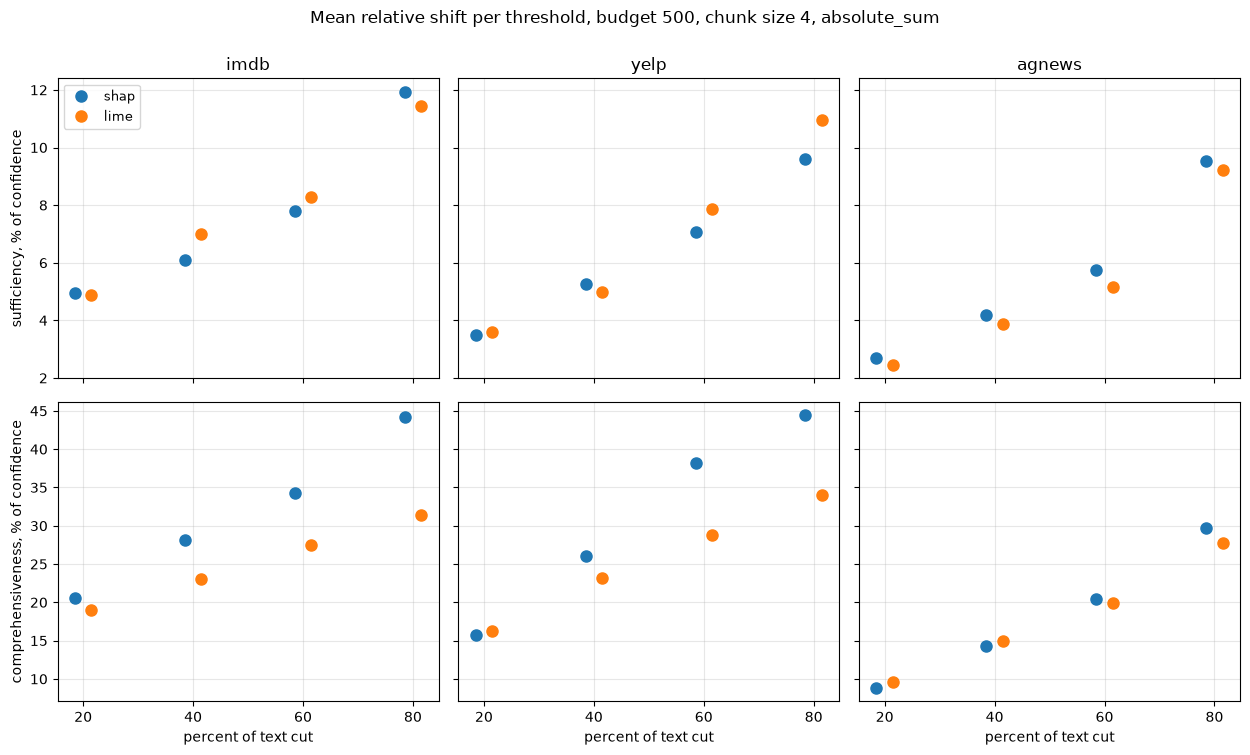

In [8]:
import matplotlib.pyplot as plt

method_colors = {"shap": "C0", "lime": "C1"}
POINTS_CHUNK_SIZE = 4
POINTS_COMBINATION = ABSOLUTE_SUM

figure, axes = plt.subplots(
    2, len(DATASET_DIRECTORIES), figsize=(4.2 * len(DATASET_DIRECTORIES), 7.5),
    sharey="row", sharex=True,
)
for column_index, dataset_name in enumerate(DATASET_DIRECTORIES):
    for row_index, direction in enumerate(["sufficiency", "comprehensiveness"]):
        axis = axes[row_index][column_index]
        for method, offset in [("shap", -1.5), ("lime", 1.5)]:
            subset = tidy[
                (tidy["dataset"] == dataset_name)
                & (tidy["source"] == f"{method}_500")
                & (tidy["chunk_size"] == POINTS_CHUNK_SIZE)
                & (tidy["combination"] == POINTS_COMBINATION)
                & (tidy["direction"] == direction)
            ]
            means = subset.groupby("percentile")["relative_shift"].mean() * 100
            axis.plot(
                means.index + offset, means.to_numpy(),
                linestyle="", marker="o", markersize=8,
                color=method_colors[method],
                label=method if row_index == 0 and column_index == 0 else None,
            )
        axis.set_xticks(PERCENTILES)
        axis.grid(alpha=0.3)
        if row_index == 0:
            axis.set_title(dataset_name)
        else:
            axis.set_xlabel("percent of text cut")

axes[0][0].set_ylabel("sufficiency, % of confidence")
axes[1][0].set_ylabel("comprehensiveness, % of confidence")
axes[0][0].legend(fontsize=9)
figure.suptitle(
    f"Mean relative shift per threshold, budget 500, chunk size "
    f"{POINTS_CHUNK_SIZE}, {POINTS_COMBINATION}",
    y=1.0,
)
figure.tight_layout()
plt.show()

## The budget ladder in percent

Threshold averaged relative scores per budget, aggregated over chunk sizes
and combinations. These texts are short, medians well under the 512 token
limit, so the budgets should be read against the word counts: at 50
evaluations LIME's surrogate sees fewer samples than most documents have
words.

In [9]:
budget_table = (
    average_shifts[average_shifts["method"].isin(["shap", "lime"])]
    .pivot_table(
        values="average_shift",
        index=["dataset", "method"],
        columns=["direction", "budget"],
        aggfunc="mean",
    )
    .reindex(
        columns=pd.MultiIndex.from_product(
            [["sufficiency", "comprehensiveness"], ["50", "200", "500"]]
        )
    )
)
(budget_table * 100).round(1)

sufficiency            comprehensiveness            
                        50   200  500                50   200   500
dataset method                                                     
agnews  lime           6.3   5.3  5.1              16.7  18.7  20.0
        shap           5.6   5.8  5.8              17.9  21.0  20.6
imdb    lime          11.8  10.6  9.3              23.5  24.7  26.8
        shap           7.9   7.8  8.2              25.7  28.7  31.6
yelp    lime          10.3   9.1  8.0              21.9  24.4  26.6
        shap           6.0   6.3  6.4              23.3  28.4  30.4

## Which combination should score a chunk?

The three combinations only differ when a chunk holds more than one word, so
chunk size 1 is excluded and the question is answered over chunk sizes 4 and
8. For each method and direction, every pair of combinations is compared per
review, per dataset and chunk size, with a Wilcoxon test per condition and a
Holm correction per family of six conditions. Positive advantage favors the
first named combination.

In [10]:
from scipy.stats import wilcoxon

COMBINATION_PAIRS = [
    (ABSOLUTE_SUM, SUM_ABSOLUTE),
    (ABSOLUTE_SUM, MAX_ABSOLUTE),
    (SUM_ABSOLUTE, MAX_ABSOLUTE),
]
CHUNKED_SIZES = [4, 8]

combination_scores = average_shifts[
    average_shifts["source"].isin(["shap_500", "lime_500"])
    & average_shifts["chunk_size"].isin(CHUNKED_SIZES)
]

combination_means = (
    combination_scores.groupby(["source", "direction", "combination"])[
        "average_shift"
    ].mean().unstack("combination") * 100
)
print("Mean relative score in percent, chunk sizes 4 and 8 pooled")
print(combination_means.round(2).to_string())
print()

by_condition = combination_scores.pivot_table(
    index=["source", "direction", "dataset", "chunk_size", "observation_index"],
    columns="combination",
    values="average_shift",
)

combination_rows = []
for source in ["shap_500", "lime_500"]:
    for direction in ["sufficiency", "comprehensiveness"]:
        for first, second in COMBINATION_PAIRS:
            p_values = []
            advantages = []
            for dataset_name in DATASET_DIRECTORIES:
                for chunk_size in CHUNKED_SIZES:
                    condition = by_condition.loc[
                        (source, direction, dataset_name, chunk_size)
                    ]
                    if direction == "sufficiency":
                        differences = (condition[second] - condition[first]).to_numpy()
                    else:
                        differences = (condition[first] - condition[second]).to_numpy()
                    advantages.append(float(differences.mean()))
                    p_values.append(float(wilcoxon(differences).pvalue))
            significant = holm_significant(np.array(p_values))
            positive = np.array(advantages) > 0
            combination_rows.append(
                {
                    "source": source,
                    "direction": direction,
                    "comparison": f"{first} vs {second}",
                    "mean_advantage_percent": float(np.mean(advantages)) * 100,
                    "significant_for_first": int((significant & positive).sum()),
                    "significant_for_second": int((significant & ~positive).sum()),
                    "conditions": len(advantages),
                }
            )

combination_comparison = pd.DataFrame(combination_rows).set_index(
    ["source", "direction", "comparison"]
)
combination_comparison.to_parquet(ARTIFACTS_DIRECTORY / "combination_comparison_v2.parquet")
combination_comparison.round(2)

Mean relative score in percent, chunk sizes 4 and 8 pooled
combination                 absolute_sum  max_absolute  sum_absolute
source   direction                                                  
lime_500 comprehensiveness         21.59         20.33         20.07
         sufficiency                6.49          7.23          7.12
shap_500 comprehensiveness         24.65         23.02         23.01
         sufficiency                6.44          7.32          6.77



mean_advantage_percent  \
source   direction         comparison                                             
shap_500 sufficiency       absolute_sum vs sum_absolute                    0.33   
                           absolute_sum vs max_absolute                    0.88   
                           sum_absolute vs max_absolute                    0.55   
         comprehensiveness absolute_sum vs sum_absolute                    1.64   
                           absolute_sum vs max_absolute                    1.63   
                           sum_absolute vs max_absolute                   -0.01   
lime_500 sufficiency       absolute_sum vs sum_absolute                    0.63   
                           absolute_sum vs max_absolute                    0.74   
                           sum_absolute vs max_absolute                    0.11   
         comprehensiveness absolute_sum vs sum_absolute                    1.53   
                           absolute_sum vs max_absolute                    1.27   
                           sum_absolute vs max_absolute                   -0.26   

                                                         significant_for_first  \
source   direction         comparison                                            
shap_500 sufficiency       absolute_sum vs sum_absolute                      1   
                           absolute_sum vs max_absolute                      5   
                           sum_absolute vs max_absolute                      0   
         comprehensiveness absolute_sum vs sum_absolute                      6   
                           absolute_sum vs max_absolute                      4   
                           sum_absolute vs max_absolute                      0   
lime_500 sufficiency       absolute_sum vs sum_absolute                      1   
                           absolute_sum vs max_absolute                      4   
                           sum_absolute vs max_absolute                      1   
         comprehensiveness absolute_sum vs sum_absolute                      2   
                           absolute_sum vs max_absolute                      1   
                           sum_absolute vs max_absolute                      0   

                                                         significant_for_second  \
source   direction         comparison                                             
shap_500 sufficiency       absolute_sum vs sum_absolute                       0   
                           absolute_sum vs max_absolute                       0   
                           sum_absolute vs max_absolute                       0   
         comprehensiveness absolute_sum vs sum_absolute                       0   
                           absolute_sum vs max_absolute                       0   
                           sum_absolute vs max_absolute                       0   
lime_500 sufficiency       absolute_sum vs sum_absolute                       0   
                           absolute_sum vs max_absolute                       0   
                           sum_absolute vs max_absolute                       0   
         comprehensiveness absolute_sum vs sum_absolute                       0   
                           absolute_sum vs max_absolute                       0   
                           sum_absolute vs max_absolute                       1   

                                                         conditions  
source   direction         comparison                                
shap_500 sufficiency       absolute_sum vs sum_absolute           6  
                           absolute_sum vs max_absolute           6  
                           sum_absolute vs max_absolute           6  
         comprehensiveness absolute_sum vs sum_absolute           6  
                           absolute_sum vs max_absolute           6  
                           sum_absolute vs max_absolute           6  
lime_500 sufficiency  

## Reading of the result

Verdicts computed from the tables above, one block per question the
conclusion of the report must answer.

In [11]:
print("1. Does the metric make sense? Every method against gaussian random")
for first in ["shap_500", "lime_500", "occlusion"]:
    subset = method_comparison.loc[f"{first} vs random"]
    survivors = subset[subset["holm_significant"]]
    print(
        f"   {first}: beats random in {int((survivors['first_advantage'] > 0).sum())} "
        f"of {len(subset)} Holm corrected conditions, loses in "
        f"{int((survivors['first_advantage'] < 0).sum())}"
    )

print()
print("2. SHAP versus LIME at 500 evaluations")
head_to_head = method_comparison.loc["shap_500 vs lime_500"]
survivors = head_to_head[head_to_head["holm_significant"]]
print(
    f"   significant conditions: {len(survivors)} of {len(head_to_head)}, "
    f"SHAP {int((survivors['first_advantage'] > 0).sum())}, "
    f"LIME {int((survivors['first_advantage'] < 0).sum())}"
)
shap_seconds = seconds_per_review.xs("shap", level="method")["500"].mean()
lime_seconds = seconds_per_review.xs("lime", level="method")["500"].mean()
print(
    f"   cost at 500: SHAP {shap_seconds:.1f} s/review, LIME {lime_seconds:.1f} "
    f"s/review on average across datasets"
)

print()
print("3. Budget ladders, full budget versus cheaper arms")
for comparison_name in [
    "shap_500 vs shap_200", "shap_200 vs shap_50", "shap_500 vs shap_50",
    "lime_500 vs lime_200", "lime_200 vs lime_50", "lime_500 vs lime_50",
]:
    subset = method_comparison.loc[comparison_name]
    survivors = subset[subset["holm_significant"]]
    print(
        f"   {comparison_name}: bigger budget better in "
        f"{int((survivors['first_advantage'] > 0).sum())} of {len(subset)}, "
        f"smaller better in {int((survivors['first_advantage'] < 0).sum())}"
    )

print()
print("4. Combination verdict per method and direction (chunked sizes only)")
for (source, direction), group in combination_means.groupby(level=[0, 1]):
    row = group.iloc[0]
    best = row.idxmin() if direction == "sufficiency" else row.idxmax()
    print(f"   {source} {direction}: best mean {best} ({row[best]:.2f}%)")

1. Does the metric make sense? Every method against gaussian random
   shap_500: beats random in 54 of 54 Holm corrected conditions, loses in 0
   lime_500: beats random in 54 of 54 Holm corrected conditions, loses in 0
   occlusion: beats random in 52 of 54 Holm corrected conditions, loses in 0

2. SHAP versus LIME at 500 evaluations
   significant conditions: 31 of 54, SHAP 25, LIME 6
   cost at 500: SHAP 7.8 s/review, LIME 18.7 s/review on average across datasets

3. Budget ladders, full budget versus cheaper arms
   shap_500 vs shap_200: bigger budget better in 8 of 54, smaller better in 0
   shap_200 vs shap_50: bigger budget better in 14 of 54, smaller better in 0
   shap_500 vs shap_50: bigger budget better in 15 of 54, smaller better in 4
   lime_500 vs lime_200: bigger budget better in 12 of 54, smaller better in 0
   lime_200 vs lime_50: bigger budget better in 13 of 54, smaller better in 0
   lime_500 vs lime_50: bigger budget better in 48 of 54, smaller better in 0

4. Comb